# Week 5 — Day 5
# Sentiment Analysis

Today we will learn:

- Positive sentiment
- Negative sentiment
- Neutral sentiment
- Sentiment classification
- Classification metrics
- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix

Main pipeline:
```text
Text
 ↓
Preprocessing
 ↓
Feature Extraction
 ↓
ML Model
 ↓
Sentiment

## What is Sentiment Analysis?

Sentiment Analysis is an NLP technique used to determine the emotional or opinion-based meaning of text.

The most common categories are:

- Positive
- Negative
- Neutral

Example:

"I love this phone."

→ Positive

"I hate this phone."

→ Negative

"This phone is okay."

→ Neutral

Sentiment Analysis = Automatically determining the sentiment expressed in text.

## Why is Sentiment Analysis Useful?

Companies receive huge amounts of text from:

- Customer reviews
- Social media
- Surveys
- Emails
- Support tickets
- Feedback forms

Manually reading every message is slow.

Sentiment Analysis can automatically identify whether customers are happy, unhappy, or neutral.

Example:
```text
10,000 customer reviews
        ↓
Sentiment Analysis
        ↓
Positive: 6,500
Negative: 2,000
Neutral: 1,500

## Positive Sentiment

Positive sentiment indicates that the person expresses a favorable opinion, satisfaction, happiness, or appreciation.

Examples:

"I loved this movie."

→ Positive

"The product is excellent."

→ Positive

"Great customer service!"

→ Positive

"I am very happy with my purchase."

→ Positive

### Common positive words:
```text
love
excellent
amazing
great
fantastic
happy
wonderful
enjoy
best

## Negative Sentiment

Negative sentiment indicates dissatisfaction, dislike, anger, disappointment, or an unfavorable opinion.

Examples:

"I hated this movie."

→ Negative

"The product is terrible."

→ Negative

"Very poor customer service."

→ Negative

"I am disappointed with my purchase."

→ Negative

### Common negative words:
```TEXT
hate
terrible
bad
poor
awful
disappointed
boring
worst
useless

## Neutral Sentiment

Neutral sentiment means the text does not clearly express a positive or negative opinion.

Examples:

"The movie starts at 7 PM."

→ Neutral

"The package arrived yesterday."

→ Neutral

"The phone has a 6.5-inch display."

→ Neutral

The text provides information without clearly expressing positive or negative emotion.

## Positive vs Negative vs Neutral

| Text | Sentiment |
|---|---|
| I love this product. | Positive |
| This product is terrible. | Negative |
| The product arrived today. | Neutral |
| Amazing service! | Positive |
| Very disappointing. | Negative |
| The product costs ₹500. | Neutral |

## Sentiment Classification

Sentiment Analysis can be treated as a text classification problem.

Input:

"I loved this movie."

Output:

Positive

Therefore:
```text
Text
 ↓
Text Classification Model
 ↓
Sentiment Class
```
#### If we have three classes:
```text
Positive
Negative
Neutral
```
this becomes a multi-class classification problem.

## Sentiment Analysis Pipeline

Example:

"I really loved this movie!"

        ↓

Preprocessing

        ↓

"really loved movie"

        ↓

Feature Extraction

        ↓

TF-IDF numerical features

        ↓

Classification Model

        ↓

Prediction

        ↓

Positive

## Training Data

A sentiment model needs labelled examples.

Example:

| Review | Sentiment |
|---|---|
| I love this product | Positive |
| Amazing experience | Positive |
| This is fantastic | Positive |
| I hate this product | Negative |
| Terrible experience | Negative |
| This is awful | Negative |
| The product arrived today | Neutral |

The model learns patterns from these examples.

Review → Input

Sentiment → Label

In [2]:
texts = [
    "I love this product",
    "This product is amazing",
    "The experience was fantastic",
    "I am very happy",
    "I hate this product",
    "This product is terrible",
    "The experience was awful",
    "I am very disappointed",
    "The product arrived today",
    "The delivery was on Monday",
    "The phone has a large screen",
    "The package contains a charger"
]

labels = [
    "Positive",
    "Positive",
    "Positive",
    "Positive",
    "Negative",
    "Negative",
    "Negative",
    "Negative",
    "Neutral",
    "Neutral",
    "Neutral",
    "Neutral"
]

print("Total examples:", len(texts))

Total examples: 12


## Training and Testing Data

We divide the dataset into two parts.

### Training Data

Used to teach the model.

### Testing Data

Used to check how well the trained model performs on unseen examples.

Example:

80% → Training

20% → Testing

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    texts,
    labels,
    test_size=0.25,
    random_state=42,
    stratify=labels
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 9
Testing examples: 3


## Feature Extraction

The model cannot directly work with sentences such as:

"I love this product."

We convert the text into numerical features.

Today we will use:

TF-IDF

Pipeline:
```text
Text
 ↓
TF-IDF
 ↓
Numbers
 ↓
Machine Learning Model

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()

X_train_features = vectorizer.fit_transform(X_train)
X_test_features = vectorizer.transform(X_test)

print("Training feature shape:", X_train_features.shape)
print("Testing feature shape:", X_test_features.shape)

Training feature shape: (9, 21)
Testing feature shape: (3, 21)


## Train the Sentiment Classifier

Now we give the numerical features to a machine learning algorithm.

We will use:

Logistic Regression

Pipeline:
```text
TF-IDF Features
       ↓
Logistic Regression
       ↓
Sentiment Prediction

In [5]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_features, y_train)

print("Sentiment model trained successfully!")

Sentiment model trained successfully!


In [6]:
predictions = model.predict(X_test_features)

print("Actual:")
print(list(y_test))

print("\nPredicted:")
print(list(predictions))

Actual:
['Positive', 'Neutral', 'Negative']

Predicted:
[np.str_('Neutral'), np.str_('Neutral'), np.str_('Neutral')]


## Predict New Reviews

After training, we can give the model completely new text.

Example:

"This product is wonderful."

The model should predict:

Positive

In [7]:
new_reviews = [
    "This product is wonderful",
    "The service was terrible",
    "The package arrived yesterday"
]

new_features = vectorizer.transform(new_reviews)

new_predictions = model.predict(new_features)

for review, sentiment in zip(new_reviews, new_predictions):
    print("Review:", review)
    print("Sentiment:", sentiment)
    print()

Review: This product is wonderful
Sentiment: Negative

Review: The service was terrible
Sentiment: Neutral

Review: The package arrived yesterday
Sentiment: Neutral



## Classification Metrics

After training a classification model, we need to measure its performance.

Common classification metrics are:

1. Accuracy
2. Precision
3. Recall
4. F1-score

Another important tool is:

5. Confusion Matrix

## Accuracy

Accuracy measures the percentage of predictions that are correct.

Formula:

Accuracy =
Correct Predictions
-------------------
Total Predictions

Example:

100 predictions

90 correct

Accuracy = 90%

In [8]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, predictions)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")

Accuracy: 0.3333333333333333
Accuracy percentage: 33.33333333333333 %


## Why Accuracy Is Not Always Enough

Suppose we have 100 emails:

95 → Not Spam
5 → Spam

A terrible model predicts:

Every email → Not Spam

It gets:

95 correct
5 incorrect

Accuracy = 95%

That sounds good.

But the model detected:

0 spam emails.

Therefore, accuracy alone can be misleading when classes are imbalanced.

This is why we also use:

- Precision
- Recall
- F1-score

## Precision

Precision answers:

"Of all the items the model predicted as positive, how many were actually positive?"

Example:

Model predicted:

10 reviews → Positive

Actually positive:

8 reviews

Precision = 8 / 10

Precision = 80%

High precision means:

When the model says "Positive", it is usually correct.

## Recall

Recall answers:

"Of all the actual positive examples, how many did the model successfully identify?"

Example:

There are actually:

20 Positive reviews

The model correctly identifies:

15

Recall = 15 / 20

Recall = 75%

High recall means:

The model finds most of the actual positive examples.

## Precision vs Recall

Precision:

"How many of my positive predictions were correct?"

Recall:

"How many of the actual positive examples did I find?"

Think:

Precision → Prediction quality

Recall → Detection coverage

## F1-Score

F1-score combines Precision and Recall into one metric.

It is useful when we want a balance between:

Precision
+
Recall

A high F1-score generally means the model has a good balance between precision and recall.

F1-score is especially useful when the dataset is not perfectly balanced.

In [9]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    predictions,
    zero_division=0
))

              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         1
     Neutral       0.33      1.00      0.50         1
    Positive       0.00      0.00      0.00         1

    accuracy                           0.33         3
   macro avg       0.11      0.33      0.17         3
weighted avg       0.11      0.33      0.17         3



## What is a Confusion Matrix?

A confusion matrix is a table that shows:

- What the actual class was
- What the model predicted

For a 3-class sentiment problem:

                Predicted
              Pos  Neg  Neutral
```text
Actual Pos
Actual Neg
Actual Neutral

## Example Confusion Matrix

Suppose our model produces:
```text
                Predicted
              Pos  Neg  Neutral

Actual Pos     8    1      1

Actual Neg     1    7      2

Actual Neutral 0    2      8

Interpretation:

Actual Positive:

8 → correctly predicted Positive

1 → incorrectly predicted Negative

1 → incorrectly predicted Neutral

Actual Negative:

7 → correctly predicted Negative

2 → incorrectly predicted Neutral

Actual Neutral:

8 → correctly predicted Neutral

In [10]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    predictions,
    labels=["Positive", "Negative", "Neutral"]
)

print(cm)

[[0 0 1]
 [0 0 1]
 [0 0 1]]


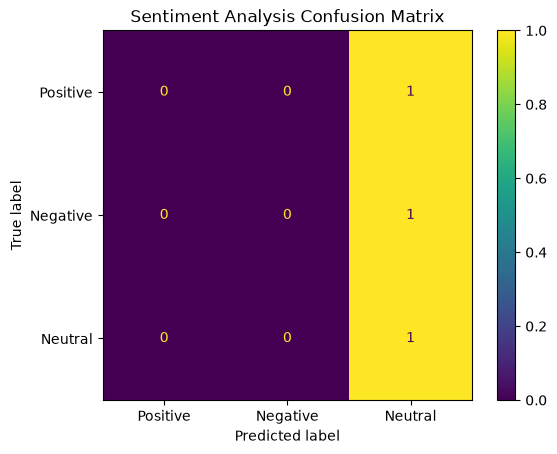

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Positive", "Negative", "Neutral"]
)

display.plot()

plt.title("Sentiment Analysis Confusion Matrix")
plt.show()

## How to Read a Confusion Matrix

The basic rule:

### Diagonal = Correct

If actual Positive → predicted Positive

That is correct.

If actual Negative → predicted Negative

That is correct.

If actual Neutral → predicted Neutral

That is correct.


### Off-diagonal = Incorrect

Actual Positive → predicted Negative

That is incorrect.

Actual Negative → predicted Neutral

That is incorrect.

Actual Neutral → predicted Positive

That is incorrect.

## TP, TN, FP and FN

For binary classification, we commonly use:

TP → True Positive

TN → True Negative

FP → False Positive

FN → False Negative


True = Prediction was correct

False = Prediction was incorrect

Positive / Negative = The predicted class

## Binary Classification Example

Imagine a model detecting positive reviews.
```text
Actual Positive
       │
       ├── Predicted Positive → TP
       │
       └── Predicted Negative → FN


Actual Negative
       │
       ├── Predicted Positive → FP
       │
       └── Predicted Negative → TN

## Classification Metrics — Quick Comparison

| Metric | Main Question |
|---|---|
| Accuracy | How many predictions were correct? |
| Precision | When the model predicts positive, how often is it correct? |
| Recall | How many actual positives did the model find? |
| F1-score | How well balanced are precision and recall? |
| Confusion Matrix | Which classes did the model confuse? |

## Challenges in Sentiment Analysis

Real-world sentiment analysis is harder than simple examples.

### Sarcasm

"Fantastic. Another two-hour delay."

The word "Fantastic" looks positive, but the sentence is negative.


### Negation

"I do not like this product."

The word "like" is positive by itself, but "do not like" is negative.


### Context

"The battery lasts only two hours."

Whether this is positive or negative depends on context.


### Mixed sentiment

"The camera is excellent, but the battery is terrible."

The same sentence contains both positive and negative opinions.

## Why Preprocessing Matters

Consider:

"I don't like this product."

If preprocessing removes "don't":

"I like this product."

The meaning has changed.

Original:

Negative

After bad preprocessing:

Positive

Therefore, preprocessing must be designed according to the NLP task.

For sentiment analysis, words related to negation can be very important.

## From Traditional NLP to Modern NLP

Our current approach:

Text
 ↓
Preprocessing
 ↓
TF-IDF
 ↓
ML Classifier
 ↓
Sentiment

This approach is useful and easy to understand.

Modern NLP often uses:

Text
 ↓
Tokenization
 ↓
Embeddings
 ↓
Neural Network
 ↓
Transformer
 ↓
Prediction

Transformers can capture much richer relationships between words and context.

We will encounter these concepts in Week 6 when we study LLMs and Transformers.

# Mini Sentiment Analysis Project

Our complete workflow:

1. Collect text data
2. Clean the text
3. Split into training and testing data
4. Convert text into TF-IDF features
5. Train a classification model
6. Predict sentiment
7. Evaluate the model
8. Analyze the confusion matrix

Pipeline:

Customer Review
      ↓
Preprocessing
      ↓
TF-IDF
      ↓
Logistic Regression
      ↓
Positive / Negative / Neutral
      ↓
Evaluation
      ↓
Accuracy / Precision / Recall / F1
      ↓
Confusion Matrix